# Our randomly initialized CNN
Three Conv/ReLU/BatchNorm/pooling blocks learn patterns from Log-Mel. A time mean retains frequency position. Cross entropy operates on logits; AdamW updates weights. Dropout and validation-based early stopping limit overfitting. No pretrained weights or AI APIs are used.

In [1]:
from pathlib import Path
import json, sys
import pandas as pd
from IPython.display import display, Image
root=Path.cwd()
if root.name != "ml": root=root/"ml"
assert Path(sys.executable).resolve()==(root/".venv/Scripts/python.exe").resolve()
sys.path.insert(0,str(root))
def read(path): return json.loads((root/path).read_text())


In [2]:
from src.models.cnn import ChordCNN
config=read("artifacts/cnn/config.json")
model=ChordCNN(len(config["class_names"]))
print(model)
print("Parameters:",sum(p.numel() for p in model.parameters()))
print(config["weights_origin"])
print("Device:",config["device"],"Batch:",config["batch_size"],"AMP:",config["amp"])

ChordCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): TemporalMean()
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1024, out_features=128, bias=True)
    (2): 

{'epoch': 27,
 'train_loss': 0.015942285779731075,
 'train_accuracy': 0.9960474308300395,
 'validation_loss': 0.043873943854123354,
 'validation_accuracy': 0.9921259842519685,
 'validation_macro_f1': 0.991919191919192,
 'gpu_peak_allocated_mib': 151.03125,
 'elapsed_seconds': 10.814228599999751}

,epoch,train_loss,train_accuracy,validation_loss,validation_accuracy,validation_macro_f1,gpu_peak_allocated_mib,elapsed_seconds
37,38,0.006552,1.000000,0.047511,0.992126,0.991919,151.03125,15.038765
38,39,0.007158,0.998024,0.050947,0.976378,0.940374,151.03125,15.407283
39,40,0.007657,1.000000,0.090212,0.976378,0.975253,151.03125,15.767803
40,41,0.003854,1.000000,0.074151,0.976378,0.940374,151.03125,16.142626
41,42,0.003650,1.000000,0.073103,0.976378,0.940374,151.03125,16.504080


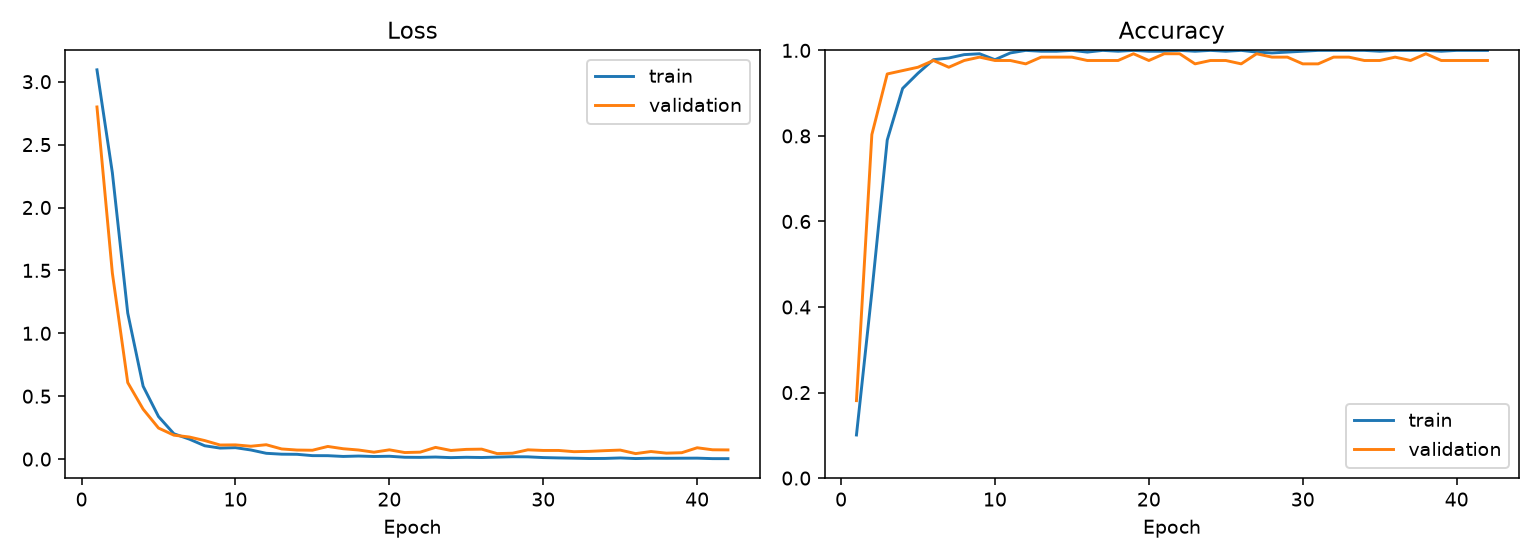

In [3]:
display(read("artifacts/cnn/best_epoch.json"))
display(pd.DataFrame(read("artifacts/cnn/history.json")).tail())
display(Image(filename=str(root/"artifacts/cnn/learning_curves.png")))

## Checkpoint and inference
The best weights and final resumable optimizer/RNG state are separate artifacts. Never overwrite the final evaluated model while experimenting. The resume test works on a separate copy. Standardization uses training-only per-band statistics saved in config.json. Run training explicitly from the CLI, not automatically by re-opening this report notebook.